In [1]:
import sys
if "../" not in sys.path:
    sys.path.append("../")
    
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.wong import sigma
from src.plot import plot_D_f
import scienceplots
plt.style.use(['science', 'no-latex', 'ieee'])

import scipy as sp
import os
from scipy.optimize import curve_fit
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, WhiteKernel, Matern, ConstantKernel, ExpSineSquared, RationalQuadratic
import findiff as fd

plt.rc('axes', labelsize=14) 
plt.rcParams['axes.titlesize'] = 20
plt.rc('xtick', labelsize=14)
plt.rc('ytick', labelsize=14)
plt.rc('legend', fontsize=10)  

save_data = True # Toggle to True to overrwite training data

Best-fit parameters:
  E0    = 73.3846 ± 0.0047 MeV
  R0    = 10.2260 ± 0.0078 fm
  hbarw = 4.8410 ± 0.0074 MeV


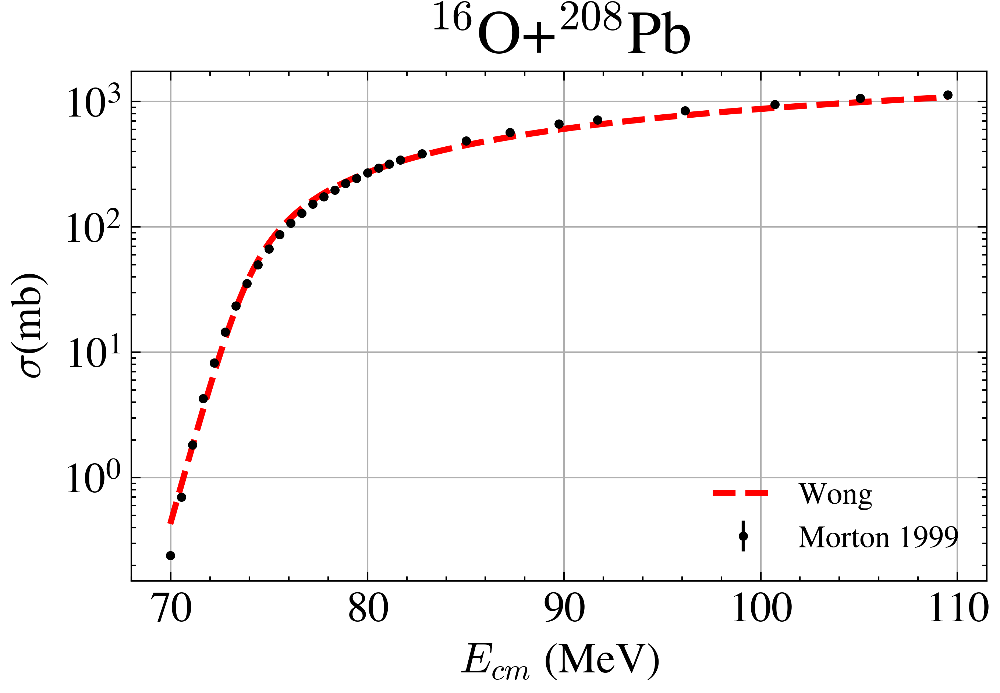

In [3]:
dirname = "../../barrier-distribution-sample/16O208Pb_exp"
system = "$^{208}$Pb+$^{16}$O"
fileprefix = dirname

expfiles = [ 'expMort.dat', 'expDas.dat' ]
explabel = [ 'Morton et al. 1999', 'Dasgupta et al. 2007' ]
expmarker = [ 'o', 's' ]
expcolor = [ 'k', 'g' ]

exp = []

for file in expfiles:
    tmpdf = pd.read_csv(os.path.join(dirname,file),sep='\s+',names=['Ecm','Sigma','Error'])
    if(tmpdf['Ecm'].iloc[0] > tmpdf['Ecm'].iloc[-1]):
        exp.append(tmpdf.iloc[::-1])
    else:
        exp.append(tmpdf)

xmin = 70.0
xmax = 90.0


E_data = exp[0]['Ecm'].to_numpy()
Sigma_data = exp[0]['Sigma'].to_numpy()
Sigma_err  = exp[0]['Error'].to_numpy()


# --- Initial guesses for [E0, R0, hbarw] ---
# You may need to tweak these based on your system.
initial_guess = [70.0, 11.0, 4]  # e.g. E0≈10MeV, R0≈7fm, ħω≈4MeV

# --- Perform the fit ---
popt, pcov = curve_fit(
    sigma,
    E_data,
    Sigma_data,
    p0=initial_guess,
    sigma=Sigma_err,
    absolute_sigma=True,
    # bounds can help keep parameters physical:
    bounds=([0.0, 8.0, 0.0], [np.inf, 15.0, np.inf])
)

E0_opt, R0_opt, hbarw_opt = popt
perr = np.sqrt(np.diag(pcov))

print(f"Best-fit parameters:")
print(f"  E0    = {E0_opt:.4f} ± {perr[0]:.4f} MeV")
print(f"  R0    = {R0_opt:.4f} ± {perr[1]:.4f} fm")
print(f"  hbarw = {hbarw_opt:.4f} ± {perr[2]:.4f} MeV")

# --- Plot experiment vs. fit ---
E_plot = np.linspace(E_data.min(), E_data.max(), 500)
Sigma_fit = sigma(E_plot, E0_opt, R0_opt, hbarw_opt)

plt.figure(figsize=(5,3))
plt.errorbar(E_data, Sigma_data, yerr=Sigma_err, fmt='o', label='Morton 1999', markersize=2)
#plt.scatter(E_data, Sigma_data, label='Morton 1999', color='k', s=10)
plt.plot(E_plot, Sigma_fit, label='Wong', linewidth=2)
plt.xlabel(r'$E_{cm}$ (MeV)')
plt.ylabel(r'$\sigma$(mb)')
plt.title("$^{16}$O+$^{208}$Pb")
plt.yscale('log')
plt.legend()
plt.grid(True)
#plt.tight_layout()
plt.show()

In [20]:
#from src.train import train_gp
from src.plot import plot_gp_with_data
from src.utils import barrier_dist, point_diff

def train_gp(E_train, sigma_mu_train, sigma_var_train, n_restarts=20, kernel=None, noise=None, log=False):
    """
    Train a Gaussian Process on 1D data with heteroscedastic noise.

    Parameters
    ----------
    E_train : array-like, shape (N,)
        Training energies.
    sigma_mu_train : array-like, shape (N,)
        Mean cross-section values at E_train.
    delta_sigma_train : array-like, shape (N,)
        Variance of cross-section at E_train (i.e., noise variances).
    n_restarts : int, optional (default=10)
        Number of restarts for the optimizer.

    Returns
    -------
    gp : GaussianProcessRegressor
        The fitted GP model.
    """
    # 1) Sort E_train for length-scale estimation
    E_sorted = np.sort(np.asarray(E_train))
    dE = np.diff(E_sorted)
    ell0 = min(np.abs(dE))
    lbound, ubound = ell0 , 10.0

    # 2) Compute signal variance from the training mean
    var_y0 = np.var(sigma_mu_train)
    print(var_y0)

    if kernel is None:
        # 3) Build kernel: Constant * RBF  + WhiteKernel
        k_rbf   = 1* RBF(length_scale=1.0, length_scale_bounds=(lbound, ubound))#ConstantKernel() length_scale_bounds=(lbound, ubound)) # *ConstantKernel(constant_value=var_y0, constant_value_bounds=(var_y0/100, var_y0*100)) 
        kernel  = k_rbf
        if noise: 
            k_noise = WhiteKernel(noise_level=1e-5 , noise_level_bounds=(1e-9, 1e-3))
            kernel  += k_noise

    if log: 
        gp = GaussianProcessRegressor(
            kernel=kernel,
            alpha= sigma_var_train / sigma_mu_train**2,
            normalize_y=False,
            n_restarts_optimizer=n_restarts
        )
        gp.fit(np.asarray(E_train).reshape(-1, 1), np.log(np.asarray(sigma_mu_train)))
    else:
        gp = GaussianProcessRegressor(
            kernel=kernel,
            alpha=sigma_var_train,
            normalize_y=False,
            n_restarts_optimizer=n_restarts
        )
        gp.fit(np.asarray(E_train).reshape(-1, 1), np.asarray(sigma_mu_train))

    return gp

In [21]:
# FINE GRID THAT WE NOW INVESTIGATE CORRUPTING
N = 1000
total_E = np.concatenate((exp[0]['Ecm'].to_numpy(), exp[1]['Ecm'].to_numpy()))
E_fine = np.linspace(total_E.min(), total_E.max(), N)
sigma_mean = sigma(E_fine, E0_opt, R0_opt, hbarw_opt )
E_eval   = np.linspace(E_fine.min() - 5, E_fine.max() + 5, 500)
n_samples = 100

# PRECOMPUTE TRUE D_f(E) ON THE FINE GRID
true_d = barrier_dist(
    E_fine,
    sigma(E_fine, E0_opt, R0_opt, hbarw_opt),
    acc=4
)

### Experiment 1: Effect of Different Noise Levels

In [5]:
# Uncomment to Create Dataset
# RNG for reproducible corruption
rng = np.random.default_rng(0)

# Experiment 1: 
noise_ratio = [5e-3, 1e-2, 1e-1, 5e-1]#[1e-16, 1e-8, 1e-4, 1e-2]
for ratio in noise_ratio:
    alpha = (ratio * sigma_mean)**2
    sigma_noisy = sigma_mean + rng.normal(0, np.sqrt(alpha))

    # use ratio in filename (e.g. 0.005 → “0.005”)
    tag = f"{ratio:.3f}"
    if save_data: 
        np.save(f"../data/alpha_{tag}.npy",            alpha)
        np.save(f"../data/sigma_train_noisy_{tag}.npy",sigma_noisy)


In [6]:
# PARAMETERS & GRIDS
noise_ratio = [5e-3, 1e-2, 1e-1, 5e-1]#[1e-16, 1e-8, 1e-4, 1e-2]
start = 0

# Create a training set for the GP:
E_train = E_fine
sigma_train = sigma_mean

# TRAIN & PREDICT — store in a dict for plotting
results = {}
for i, ratio in enumerate(noise_ratio):
    tag = f"{ratio:.3f}"
    alpha       = np.load(f"../data/alpha_{tag}.npy")
    sigma_train_noisy = np.load(f"../data/sigma_train_noisy_{tag}.npy")
    gp = train_gp(E_train, sigma_train_noisy, alpha)
    mu, std          = gp.predict(E_eval.reshape(-1, 1), return_std=True)
    samples          = gp.sample_y(E_eval.reshape(-1, 1), n_samples=n_samples)
    results[i] = {
        'gp': gp,
        'mu': mu,
        'std': std,
        'samples': samples,
        'ratio': ratio
    }

132351.21691872197


/Users/aaronphilip/envs/autobnn/lib/python3.10/site-packages/sklearn/gaussian_process/_gpr.py:659: ConvergenceWarning: lbfgs failed to converge (status=2):
ABNORMAL: .

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/Users/aaronphilip/envs/autobnn/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:452: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__constant_value is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


132239.59375700745


/Users/aaronphilip/envs/autobnn/lib/python3.10/site-packages/sklearn/gaussian_process/_gpr.py:659: ConvergenceWarning: lbfgs failed to converge (status=2):
ABNORMAL: .

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/Users/aaronphilip/envs/autobnn/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:452: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__constant_value is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


134605.49126061148


/Users/aaronphilip/envs/autobnn/lib/python3.10/site-packages/sklearn/gaussian_process/_gpr.py:659: ConvergenceWarning: lbfgs failed to converge (status=2):
ABNORMAL: .

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/Users/aaronphilip/envs/autobnn/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:452: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__constant_value is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


234497.04335447043


/Users/aaronphilip/envs/autobnn/lib/python3.10/site-packages/sklearn/gaussian_process/_gpr.py:659: ConvergenceWarning: lbfgs failed to converge (status=2):
ABNORMAL: .

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/Users/aaronphilip/envs/autobnn/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:452: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__constant_value is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


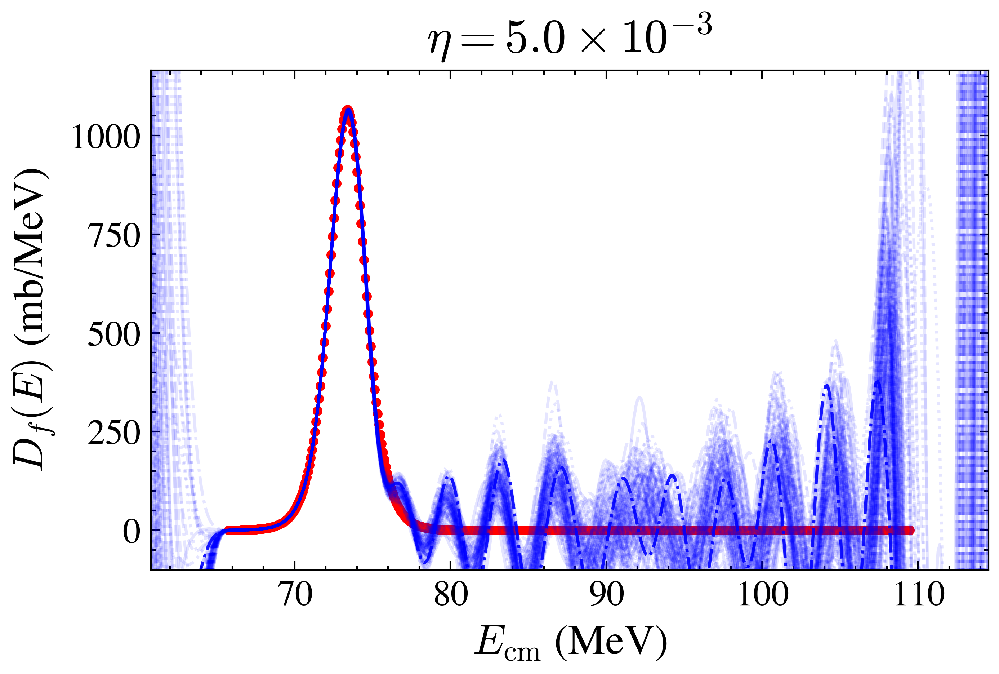

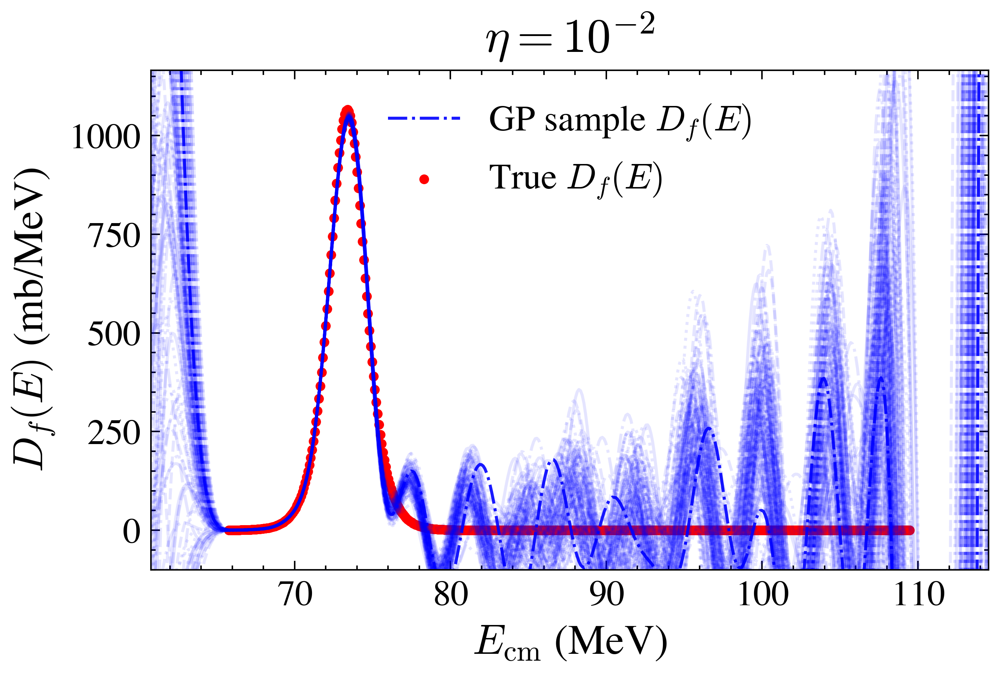

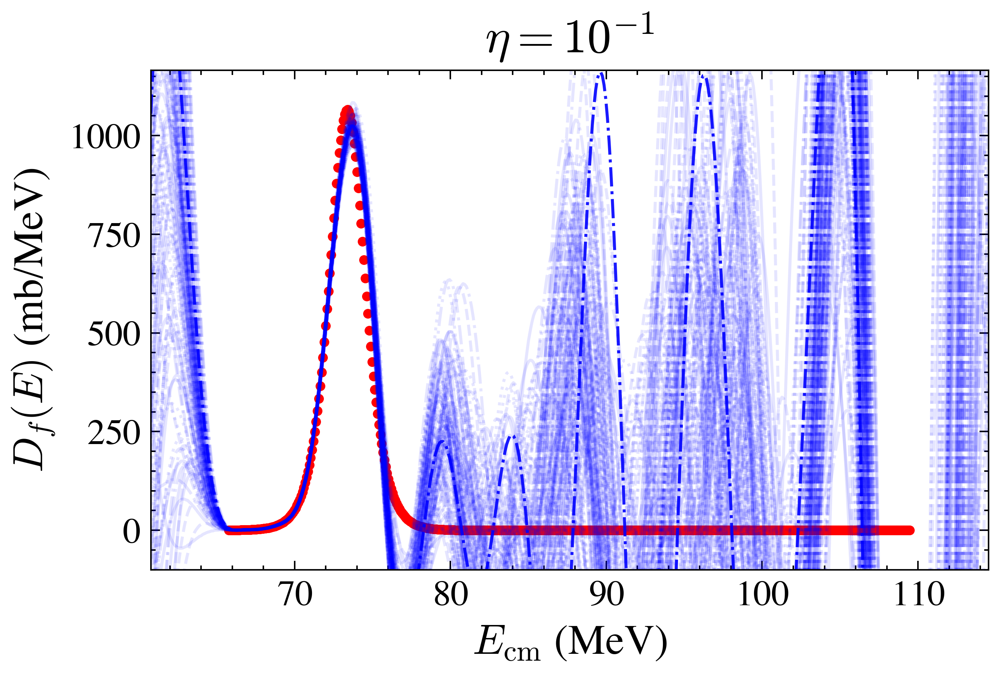

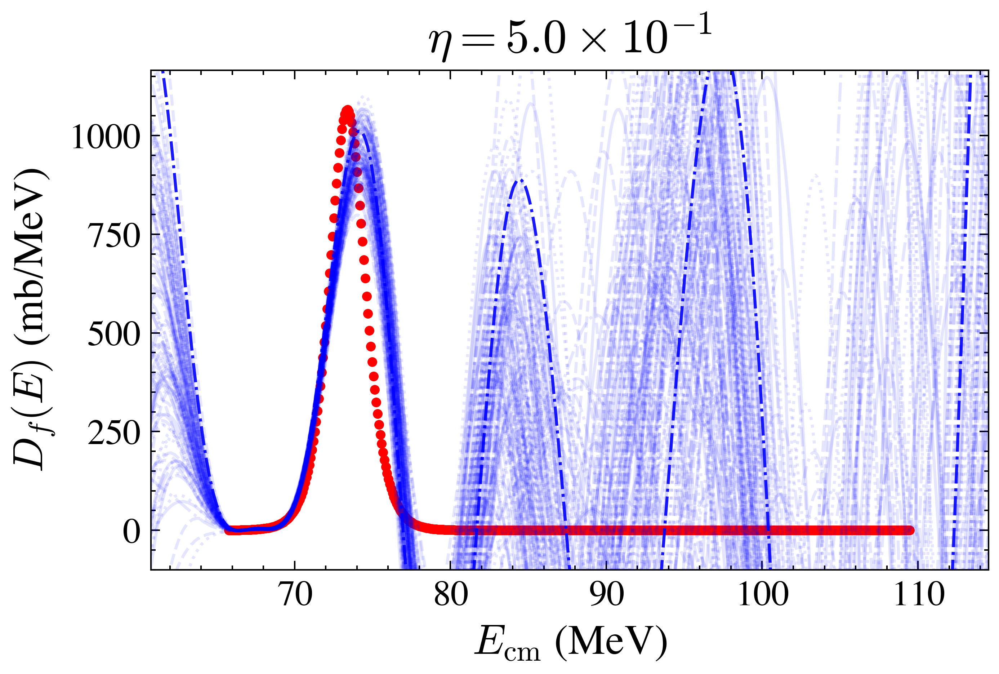

In [7]:
labeled = False
for i, data in results.items():
    mu      = data['mu']
    std     = data['std']
    samples = data['samples']
    ratio =     data['ratio']
    tag     = f"{i}"
    var = (ratio*sigma_train)**2.0
    
    e = int(np.floor(np.log10(ratio)))
    # 2) get mantissa m so that η = m × 10^e
    m = ratio / 10**e

    # 3) build title
    if np.isclose(m, 1.0):
        # pure power of ten
        title = rf"$\eta = 10^{{{e}}}$"
    else:
        # include mantissa
        title = rf"$\eta = {m:.1f}\times 10^{{{e}}}$"

    # 1) σ(E) fit + 95% CI
    fig, ax = plt.subplots(figsize=(5,3))
    ax.plot(E_eval, mu, lw=2, label="GP mean")
    ax.plot(
        E_eval,
        sigma(E_eval, E0_opt, R0_opt, hbarw_opt),
        linestyle="--", color="C1", label="Wong"
    )
    ax.fill_between(
        E_eval,
        mu - 1.96 * std,
        mu + 1.96 * std,
        alpha=0.3,
        label="95% CI"
    )
    # 1c) scatter the training points (no error-bars), small markers, on top
    ax.scatter(
        E_train,
        sigma_train,
        s=2,               # area in points^2; adjust smaller/larger as you like
        color='red',
        label="Training pts",
        zorder=5
    )
    ax.set_title(title, fontsize=16)
    ax.set_xlabel(r'$E_{\mathrm{cm}}$ (MeV)', fontsize=14)
    ax.set_ylabel(r'$\sigma(E)$', fontsize=14)
    ax.set_xlim(E_eval[0], E_eval[-1])
    if i==1: 
        ax.legend(fontsize=12)
    ax.tick_params(labelsize=12)
    fig.savefig(f'../plots/gp_sigma_var_{tag}.png', dpi=300)
    plt.close(fig)

    # 2) Barrier distributions
    fig, ax = plt.subplots(figsize=(5,3))
    for j in range(samples.shape[1]):
        style = dict(alpha=0.1, color='b')
        if j == samples.shape[1] - 1:
            style.update(alpha=0.9, label=r"GP sample $D_f(E)$")
        ax.plot(E_eval, barrier_dist(E_eval, samples[:, j], acc=4), **style)

    ax.scatter(
        E_train[::2],
        true_d[::2],
        s=5,
        color='r',
        label=r"True $D_f(E)$"
    )
    ax.set_title(title, fontsize=16)
    ax.set_xlabel(r'$E_{\mathrm{cm}}$ (MeV)', fontsize=14)
    ax.set_ylabel(r'$D_f(E)$ (mb/MeV)', fontsize=14)
    ax.set_xlim(E_train[0]-5, E_train[-1]+5)
    ax.set_ylim(true_d.min()-100, true_d.max()+100)
    if i==1: 
        ax.legend(fontsize=12)
        labeled = True
    ax.tick_params(labelsize=12)
    fig.savefig(f'../plots/gp_barrier_var_{tag}.png', dpi=300)
    plt.show()
    plt.close(fig)

### Experiment 2: Effect of White Noise Kernel

In [8]:
# Create a training set for the GP:
E_train = E_fine
sigma_train = sigma_mean

# TRAIN & PREDICT — store in a dict for plotting
results_noise = {}
for i, ratio in enumerate(noise_ratio):
    tag = f"{ratio:.3f}"
    alpha       = np.load(f"../data/alpha_{tag}.npy")
    sigma_train_noisy = np.load(f"../data/sigma_train_noisy_{tag}.npy")
    gp = train_gp(E_train, sigma_train_noisy, alpha, noise=True)
    mu, std          = gp.predict(E_eval.reshape(-1, 1), return_std=True)
    samples          = gp.sample_y(E_eval.reshape(-1, 1), n_samples=n_samples)
    exponent         = int(np.log10(ratio))
    results_noise[i] = {
        'gp': gp,
        'mu': mu,
        'std': std,
        'samples': samples,
        'exp': exponent,
        'ratio': ratio
    }

132351.21691872197


/Users/aaronphilip/envs/autobnn/lib/python3.10/site-packages/sklearn/gaussian_process/_gpr.py:659: ConvergenceWarning: lbfgs failed to converge (status=2):
ABNORMAL: .

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/Users/aaronphilip/envs/autobnn/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:452: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k1__constant_value is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/aaronphilip/envs/autobnn/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-09. Decreasing the bound and calling fit again may find a better value.
  warnings.war

132239.59375700745


/Users/aaronphilip/envs/autobnn/lib/python3.10/site-packages/sklearn/gaussian_process/_gpr.py:659: ConvergenceWarning: lbfgs failed to converge (status=2):
ABNORMAL: .

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/Users/aaronphilip/envs/autobnn/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:452: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k1__constant_value is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/aaronphilip/envs/autobnn/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-09. Decreasing the bound and calling fit again may find a better value.
  warnings.war

134605.49126061148


/Users/aaronphilip/envs/autobnn/lib/python3.10/site-packages/sklearn/gaussian_process/_gpr.py:659: ConvergenceWarning: lbfgs failed to converge (status=2):
ABNORMAL: .

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/Users/aaronphilip/envs/autobnn/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:452: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k1__constant_value is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/aaronphilip/envs/autobnn/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-09. Decreasing the bound and calling fit again may find a better value.
  warnings.war

234497.04335447043


/Users/aaronphilip/envs/autobnn/lib/python3.10/site-packages/sklearn/gaussian_process/_gpr.py:659: ConvergenceWarning: lbfgs failed to converge (status=2):
ABNORMAL: .

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/Users/aaronphilip/envs/autobnn/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:452: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k1__constant_value is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/aaronphilip/envs/autobnn/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-09. Decreasing the bound and calling fit again may find a better value.
  warnings.war

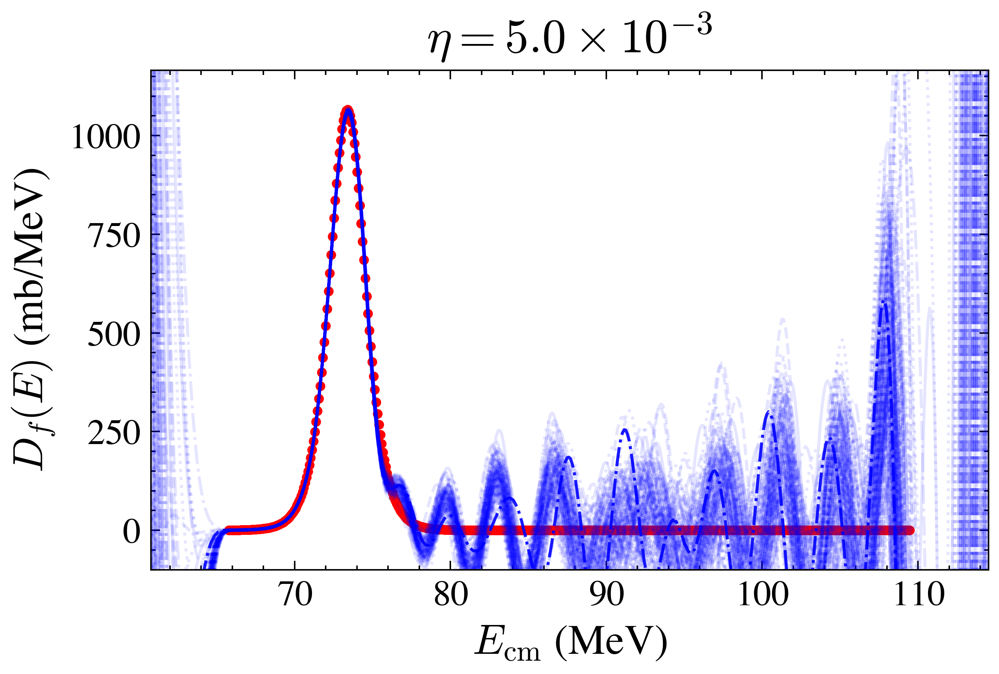

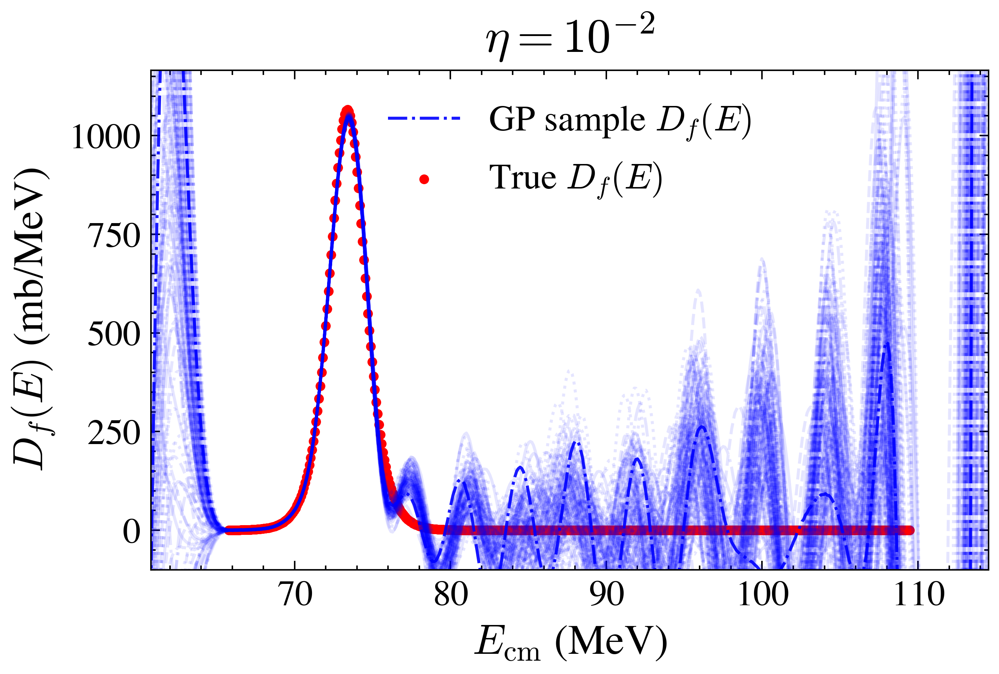

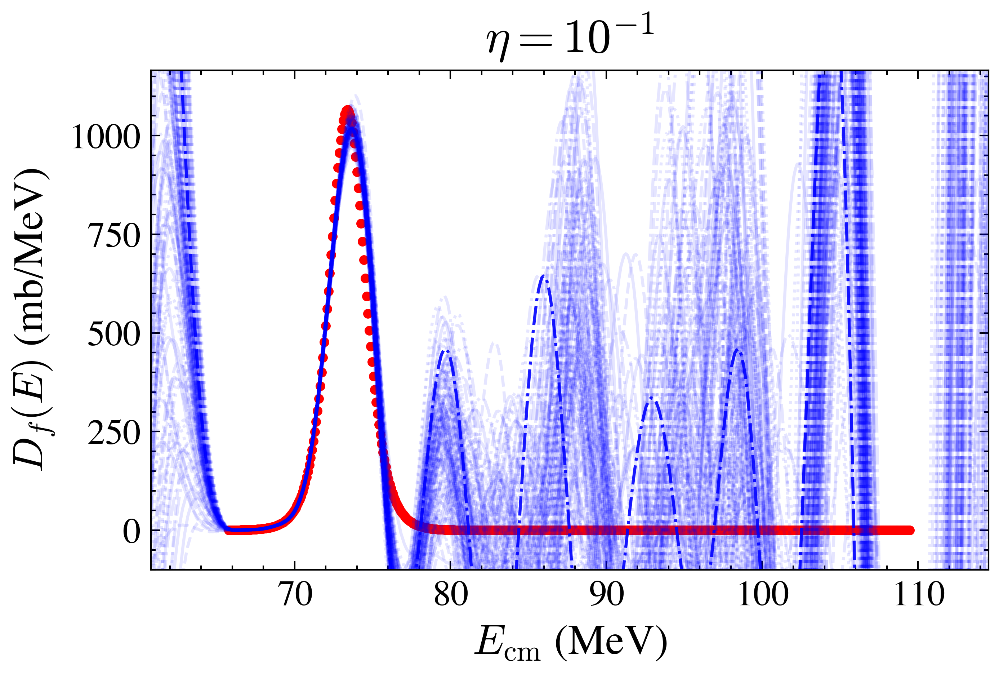

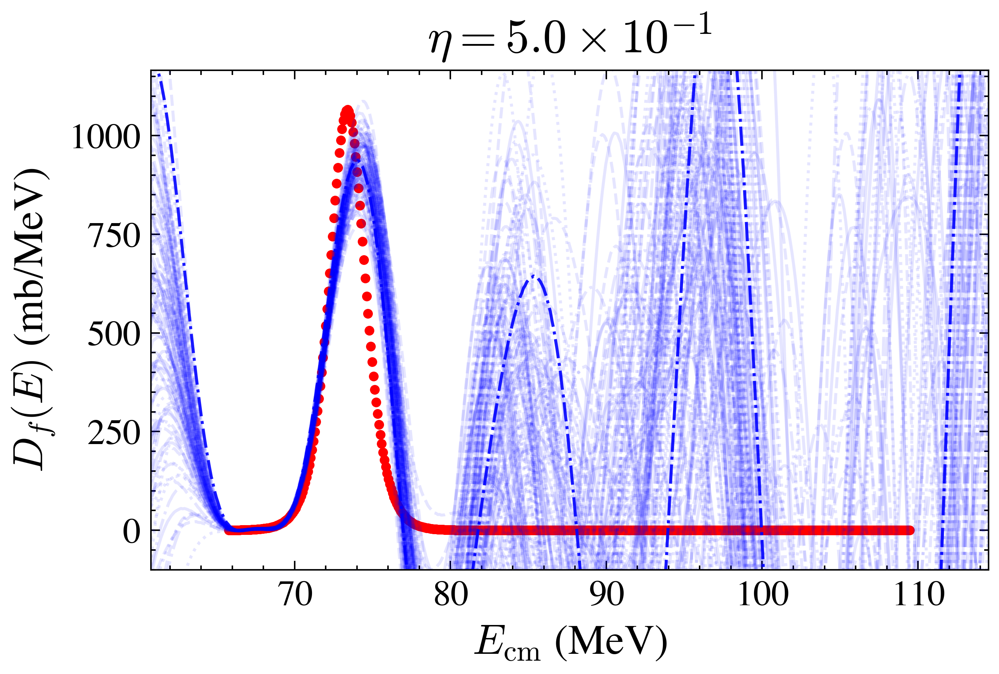

In [10]:
labeled = False
for i, data in results_noise.items():
    mu      = data['mu']
    std     = data['std']
    samples = data['samples']
    ratio =     data['ratio']
    tag     = f"{i}"
    var = (ratio*sigma_train)**2.0
    
    e = int(np.floor(np.log10(ratio)))
    # 2) get mantissa m so that η = m × 10^e
    m = ratio / 10**e

    # 3) build title
    if np.isclose(m, 1.0):
        # pure power of ten
        title = rf"$\eta = 10^{{{e}}}$"
    else:
        # include mantissa
        title = rf"$\eta = {m:.1f}\times 10^{{{e}}}$"
    # 1) σ(E) fit + 95% CI
    fig, ax = plt.subplots(figsize=(5,3))
    ax.plot(E_eval, mu, lw=2, label="GP mean")
    ax.plot(
        E_eval,
        sigma(E_eval, E0_opt, R0_opt, hbarw_opt),
        linestyle="--", color="C1", label="Wong"
    )
    ax.fill_between(
        E_eval,
        mu - 1.96 * std,
        mu + 1.96 * std,
        alpha=0.3,
        label="95% CI"
    )
    ax.scatter(
        E_train,
        sigma_train,
        s=10,               # area in points^2; adjust smaller/larger as you like
        color='red',
        label="Training pts",
        zorder=5
    )
    ax.set_title(title, fontsize=16)
    ax.set_xlabel(r'$E_{\mathrm{cm}}$ (MeV)', fontsize=14)
    ax.set_ylabel(r'$\sigma(E)$', fontsize=14)
    ax.set_xlim(E_eval[0], E_eval[-1])
    if i ==1: 
        ax.legend(fontsize=12)
    ax.tick_params(labelsize=12)
    fig.savefig(f'../plots/gp_sigma_var_{tag}_noise.png', dpi=300)
    plt.close(fig)

    # 2) Barrier distributions
    fig, ax = plt.subplots(figsize=(5,3))
    for j in range(samples.shape[1]):
        style = dict(alpha=0.1, color='b')
        if j == samples.shape[1] - 1:
            style.update(alpha=0.9, label=r"GP sample $D_f(E)$")
        ax.plot(E_eval, barrier_dist(E_eval, samples[:, j], acc=4), **style)

    ax.scatter(
        E_train[::2],
        true_d[::2],
        s=5,
        color='r',
        label=r"True $D_f(E)$"
    )
    ax.set_title(title, fontsize=16)
    ax.set_xlabel(r'$E_{\mathrm{cm}}$ (MeV)', fontsize=14)
    ax.set_ylabel(r'$D_f(E)$ (mb/MeV)', fontsize=14)
    ax.set_xlim(E_train[0]-5, E_train[-1]+5)
    ax.set_ylim(true_d.min()-100, true_d.max()+100)
    if i==1: 
        ax.legend(fontsize=12)
        labeled = True
    ax.tick_params(labelsize=12)
    fig.savefig(f'../plots/gp_barrier_var_{tag}_noise.png', dpi=300)
    plt.show()
    plt.close(fig)

### Experiment 3: Effect of Resolution at noise ratio 10^-1

In [5]:
factors = [5, 10, 20, 40]
rng     = np.random.default_rng()
#stop = np.argmin(np.abs(E_fine - 100.0))
for f in factors:
    # 1) coarsen
    E_tr       = E_fine[::f]
    E_dist     = np.arange(E_tr[0] - 5, E_tr[-1] + 5, 0.2)
    y_tr       = sigma_mean[::f]
    var_tr     = (0.1 * y_tr)**2
    y_tr_noisy = y_tr + rng.normal(0, np.sqrt(var_tr))
    var_tr_1e_2     = (0.01 * y_tr)**2
    y_tr_noisy_1e_2 = y_tr + rng.normal(0, np.sqrt(var_tr_1e_2))

    tag = str(f)
    if save_data:
        np.save(f"../data/E_tr_{tag}.npy",          E_tr)
        np.save(f"../data/E_dist_{tag}.npy",        E_dist)
        np.save(f"../data/y_tr_noisy_{tag}_1e-1.npy",    y_tr_noisy)
        np.save(f"../data/y_tr_noisy_{tag}_1e-2.npy",    y_tr_noisy_1e_2)
        np.save(f"../data/var_tr_{tag}_1e-1.npy",        var_tr)
        np.save(f"../data/var_tr_{tag}_1e-2.npy",        var_tr_1e_2)


In [22]:
# LOAD AND TRAIN
factors = [5,10,20,40]
barrier_results = {}

log = True
for f in factors:
    tag = str(f)
    E_tr       = np.load(f"../data/E_tr_{tag}.npy")
    E_dist     = np.load(f"../data/E_dist_{tag}.npy")
    y_tr_noisy = np.load(f"../data/y_tr_noisy_{tag}_1e-1.npy")
    var_tr     = np.load(f"../data/var_tr_{tag}_1e-1.npy")

    gp = train_gp(E_tr, y_tr_noisy, var_tr, log=log)
    samples = np.exp(gp.sample_y(E_dist.reshape(-1, 1), n_samples=n_samples)) if log else gp.sample_y(E_dist.reshape(-1, 1), n_samples=n_samples)
    barrier_results[f] = {
        "E_tr": E_tr,
        "samples": samples,
        "E_dist": E_dist
    }

130696.30325156204
141175.77083295176
140428.80056605712
132862.4489366553


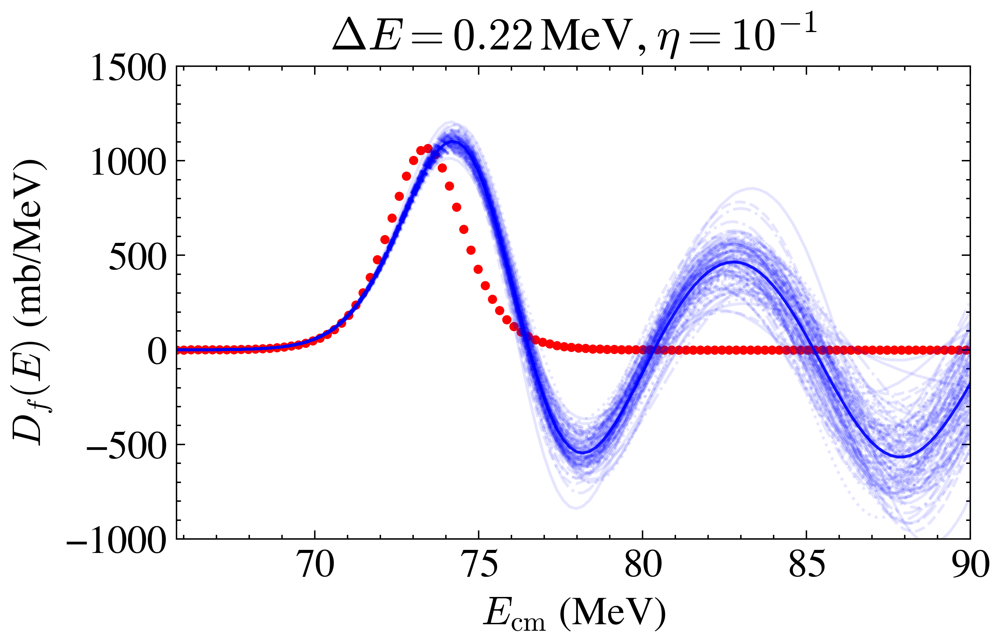

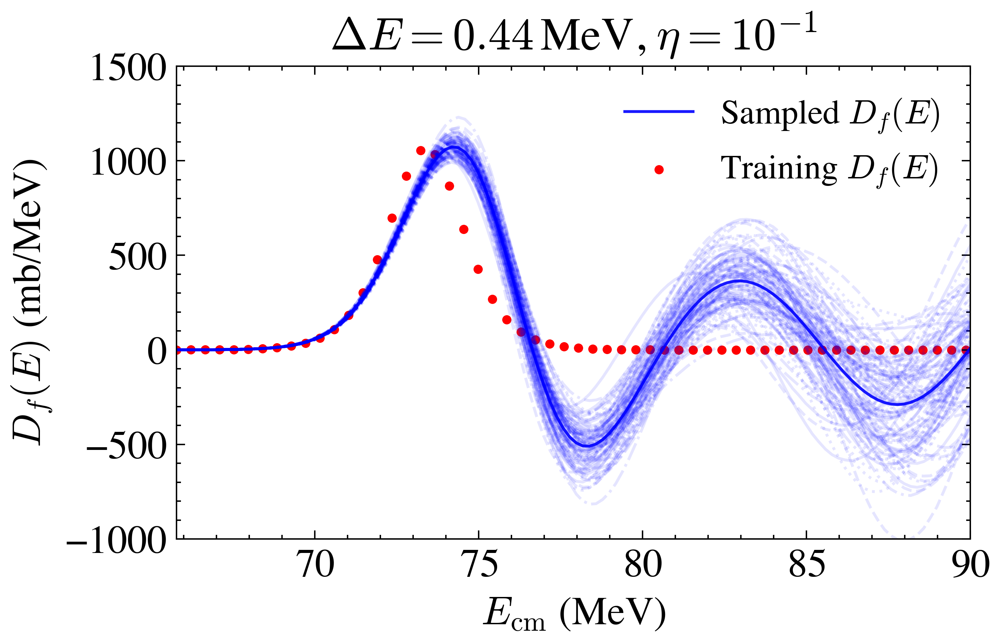

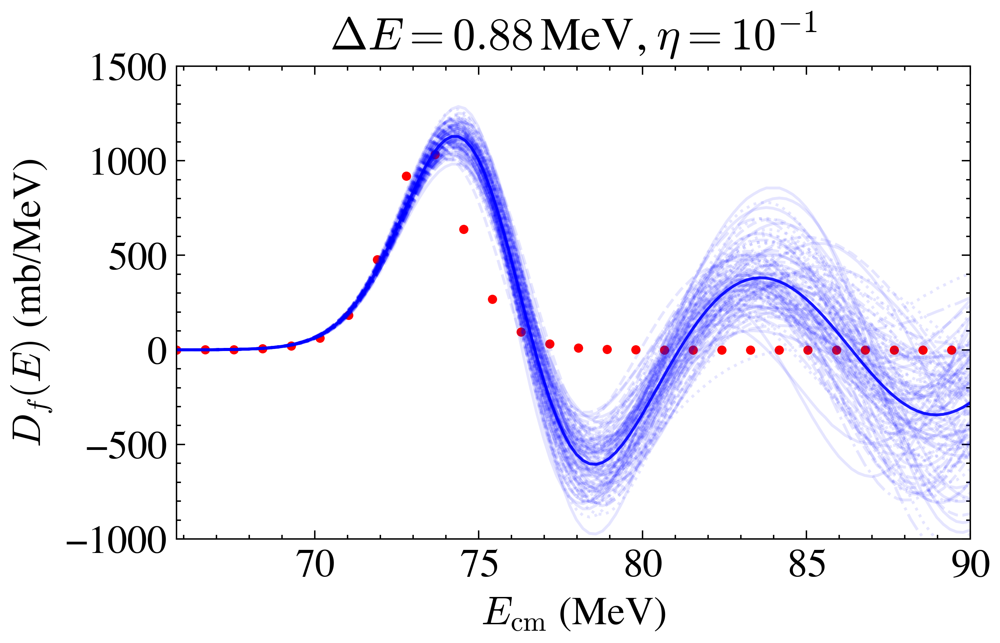

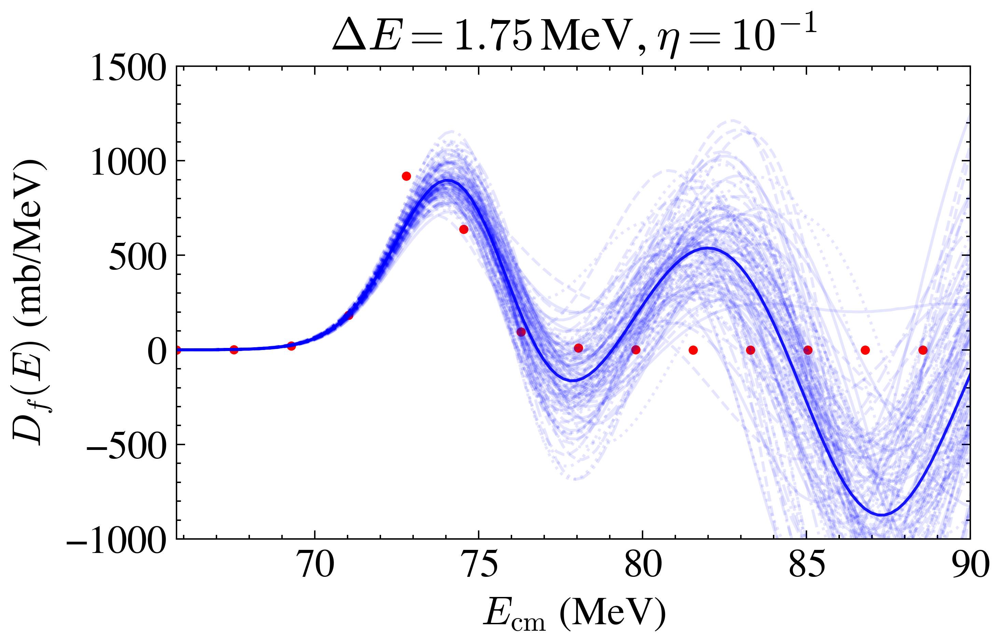

In [23]:
for f, data in barrier_results.items():
    E_tr    = data["E_tr"]
    samples = data["samples"]
    E_dist = data['E_dist']
    dE = E_tr[1] - E_tr[0]
    idx = np.searchsorted(E_fine, E_tr)
    true_d_train = true_d[idx]
    D_f_sampled_preds = np.vstack([
        barrier_dist(E_dist, samples[:, j], acc=4)
        for j in range(samples.shape[1])
    ])

    plot_D_f(
        E_train=E_tr,
        d2_train=true_d_train,
        E_pred=E_dist,
        D_f_sampled_preds=D_f_sampled_preds,
        title = f"$\\Delta E = {dE:.2f}\\,$MeV, $\\eta = 10^{{-1}}$",
        title_fontsize=16,
        axes_fontsize=14,
        legend_fontsize=12,
        xlims=[E_tr[0], 90],
        ylims=[-1000,1500],
        save_dir="../plots",                        # so it writes into ../plots/
        save_extra=f"log_barrier_coarse_{f}_e-1" if log else f"barrier_coarse_{f}_e-1",
        legend=True if f==10 else False       # becomes plot_barrier_coarse_{f}_e-1.png
    )

### Experiment 3: Effect of Resolution at noise ratio $10^{-2}$

In [24]:
factors = [5,10,20,40]
barrier_results_2 = {}

log = True
for f in factors:
    tag = str(f)
    E_tr       = np.load(f"../data/E_tr_{tag}.npy")
    E_dist     = np.load(f"../data/E_dist_{tag}.npy")
    y_tr_noisy = np.load(f"../data/y_tr_noisy_{tag}_1e-2.npy")
    var_tr     = np.load(f"../data/var_tr_{tag}_1e-2.npy")

    gp = train_gp(E_tr, y_tr_noisy, var_tr, log=log)
    samples = np.exp(gp.sample_y(E_dist.reshape(-1, 1), n_samples=n_samples)) if log else gp.sample_y(E_dist.reshape(-1, 1), n_samples=n_samples)
    barrier_results_2[f] = {
        "E_tr": E_tr,
        "E_dist": E_dist,
        "samples": samples
    }

132387.2278313183
132299.345152607
132060.05999373322


/Users/aaronphilip/envs/autobnn/lib/python3.10/site-packages/sklearn/gaussian_process/_gpr.py:659: ConvergenceWarning: lbfgs failed to converge (status=2):
ABNORMAL: .

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)


129991.97645794222


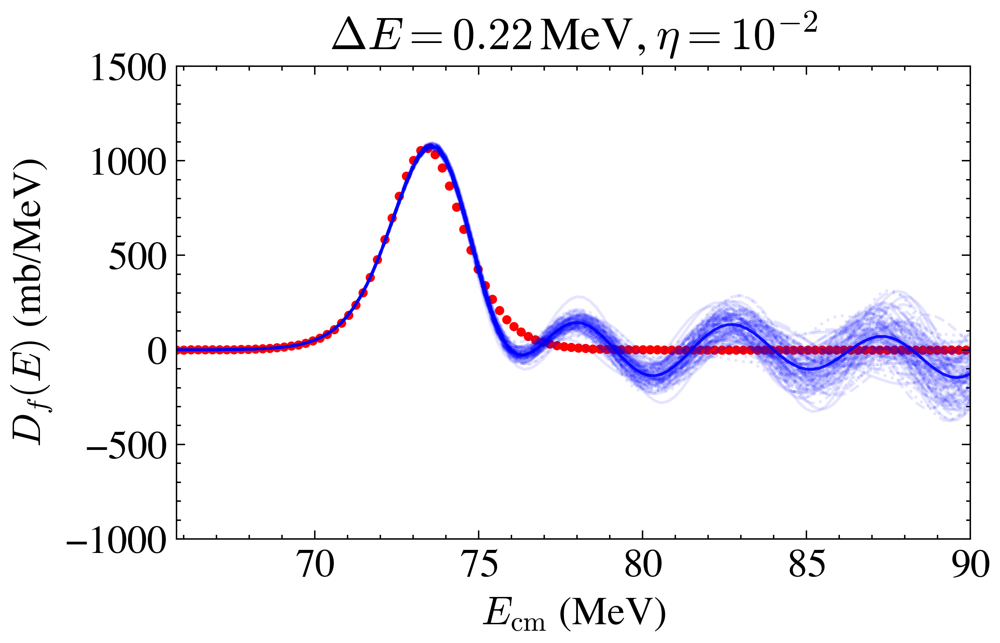

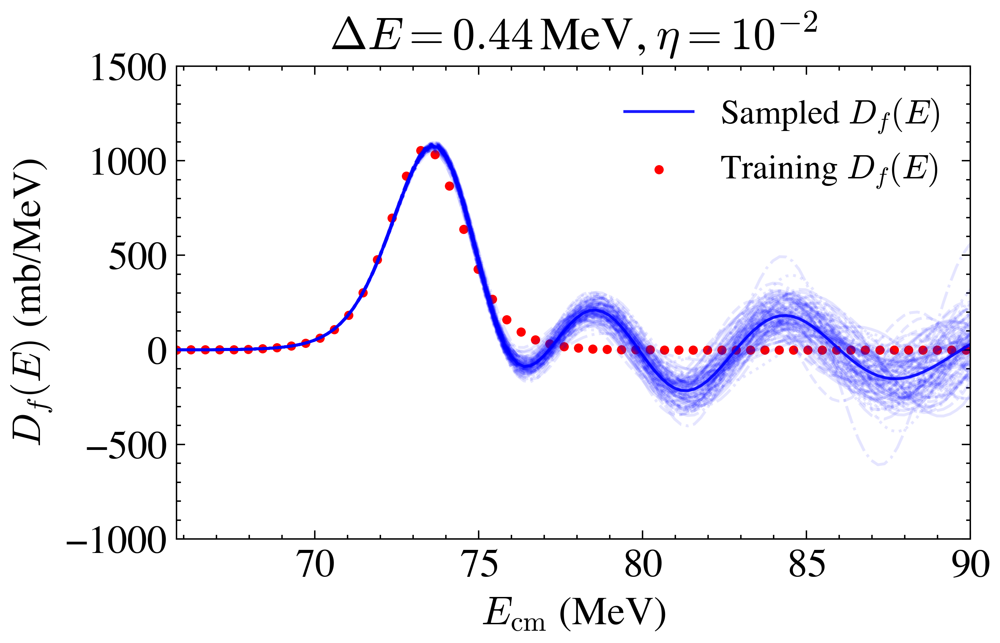

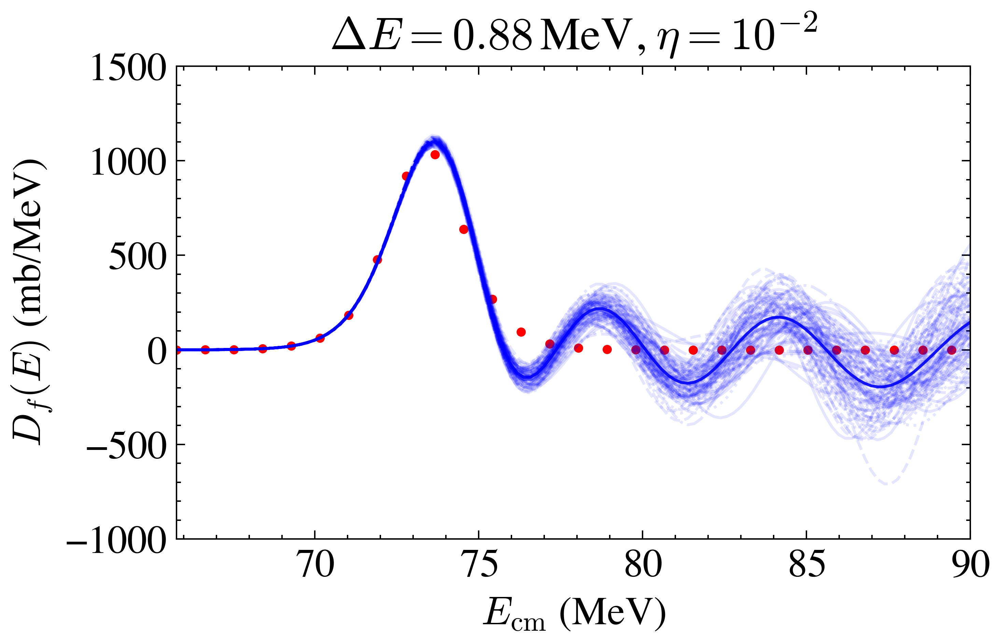

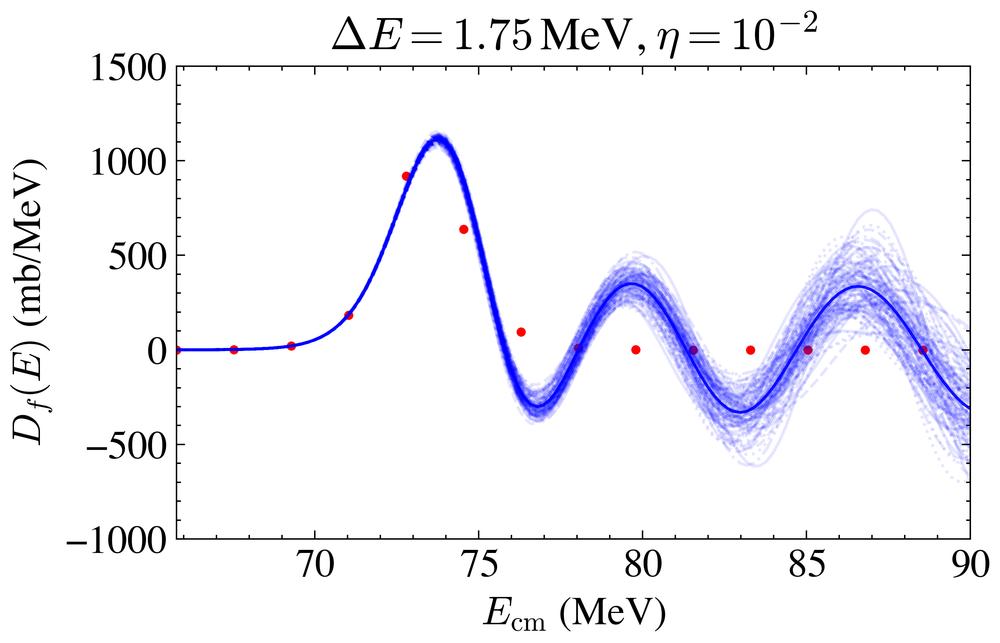

In [25]:
for f, data in barrier_results_2.items():
    E_tr    = data["E_tr"]
    samples = data["samples"]
    E_dist = data["E_dist"]
    dE = E_tr[1] - E_tr[0]
    idx = np.searchsorted(E_fine, E_tr)
    true_d_train = true_d[idx]
    D_f_sampled_preds = np.vstack([
        barrier_dist(E_dist, samples[:, j], acc=4)
        for j in range(samples.shape[1])
    ])


    plot_D_f(
        E_train=E_tr,
        d2_train=true_d_train,
        E_pred=E_dist,
        D_f_sampled_preds=D_f_sampled_preds,
        title = f"$\\Delta E = {dE:.2f}\\,$MeV, $\\eta = 10^{{-2}}$",
        title_fontsize=16,
        axes_fontsize=14,
        legend_fontsize=12,
        xlims=[E_tr[0], 90],
        ylims=[-1000,1500],
        save_dir="../plots",                              # so it writes into ../plots/
        save_extra=f"log_barrier_coarse_{f}_e-2" if log else f"barrier_coarse_{f}_e-2",
        legend=True if f==10 else False       # becomes plot_barrier_coarse_{f}_e-1.png
    )

### Experiment 4: Irregularity of Data, Average spacing of 0.5 MeV

In [14]:
cv_values    = [0.0, 0.25, 0.5, 0.75]
mean_spacing = 0.5   # MeV
rng          = np.random.default_rng(0)

# find your limits from existing E_fine
stop_idx = -1#np.argmin(np.abs(E_fine - 80.0))
E_min, E_max = E_fine[0], E_fine[stop_idx]

# evaluation grid — save once
E_dist = np.arange(E_min - 5, E_max + 5, 0.2)
if save_data:
    np.save("../data/E_dist_cv.npy", E_dist)

for cv in cv_values:
    std_sp = mean_spacing * cv
    N      = int((E_max - E_min) / mean_spacing) + 5

    # 1) build irregular E_tr
    dE_sim = np.random.normal(mean_spacing, std_sp, size=N)
    dE_sim = np.clip(dE_sim, 1e-3, None)
    E_tr   = E_min + np.cumsum(dE_sim)
    E_tr   = E_tr[E_tr <= E_max]

    # 2) interpolate and corrupt
    y_tr       = np.interp(E_tr, E_fine[:stop_idx], sigma_mean[:stop_idx])
    var_tr     = (0.01 * y_tr)**2
    y_tr_noisy = y_tr + rng.normal(0, np.sqrt(var_tr), size=y_tr.shape)

    tag = f"{cv:.2f}"
    if save_data:
        np.save(f"../data/E_tr_cv_{tag}.npy",       E_tr)
        np.save(f"../data/y_tr_cv_{tag}.npy",       y_tr)
        np.save(f"../data/var_tr_cv_{tag}.npy",     var_tr)
        np.save(f"../data/y_tr_noisy_cv_{tag}.npy", y_tr_noisy)



In [ ]:
cv_values = [0.0, 0.25, 0.5, 0.75]
mean_spacing = 0.5 # 0.5   # MeV
barrier_results_cv = {}

log=True
for cv in cv_values:
    tag       = f"{cv:.2f}"
    E_tr      = np.load(f"../data/E_tr_cv_{tag}.npy")
    y_tr_noisy= np.load(f"../data/y_tr_noisy_cv_{tag}.npy")
    var_tr    = np.load(f"../data/var_tr_cv_{tag}.npy")

    gp = train_gp(E_tr, y_tr_noisy, var_tr, log=log)
    samples = np.exp(gp.sample_y(E_dist.reshape(-1, 1), n_samples=n_samples)) if log else gp.sample_y(E_dist.reshape(-1, 1), n_samples=n_samples)

    barrier_results_cv[cv] = {
        "E_tr":    E_tr,
        "y_tr":    y_tr_noisy,
        "var_tr":  var_tr,
        "samples": samples
    }

131948.0765777797
134761.33415238134
129307.35742426469


/Users/aaronphilip/envs/autobnn/lib/python3.10/site-packages/sklearn/gaussian_process/_gpr.py:659: ConvergenceWarning: lbfgs failed to converge (status=2):
ABNORMAL: .

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)


128352.84145852155


/Users/aaronphilip/envs/autobnn/lib/python3.10/site-packages/sklearn/gaussian_process/_gpr.py:659: ConvergenceWarning: lbfgs failed to converge (status=2):
ABNORMAL: .

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)


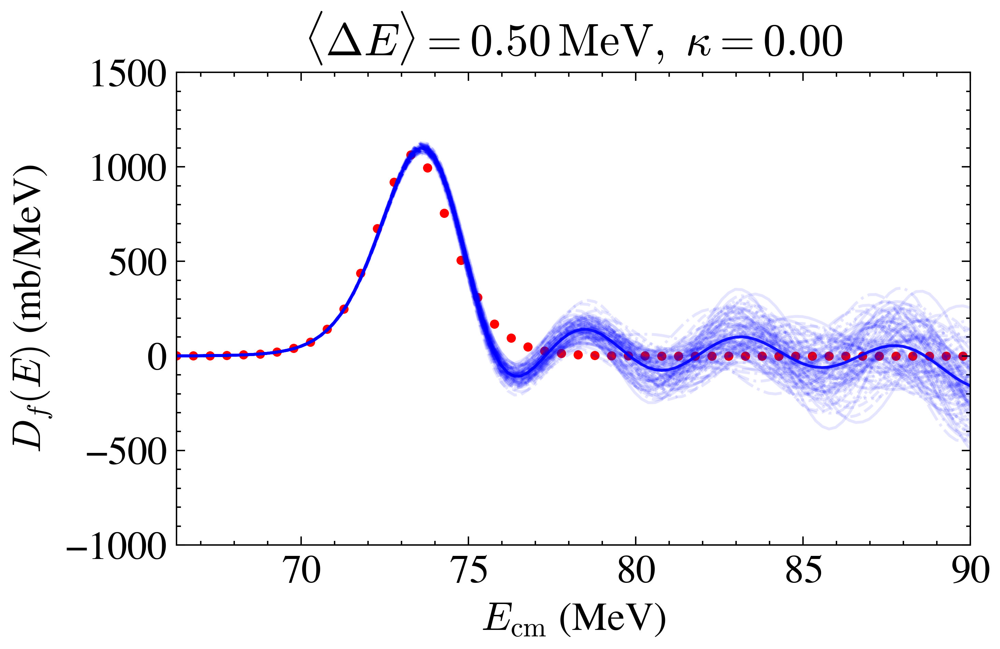

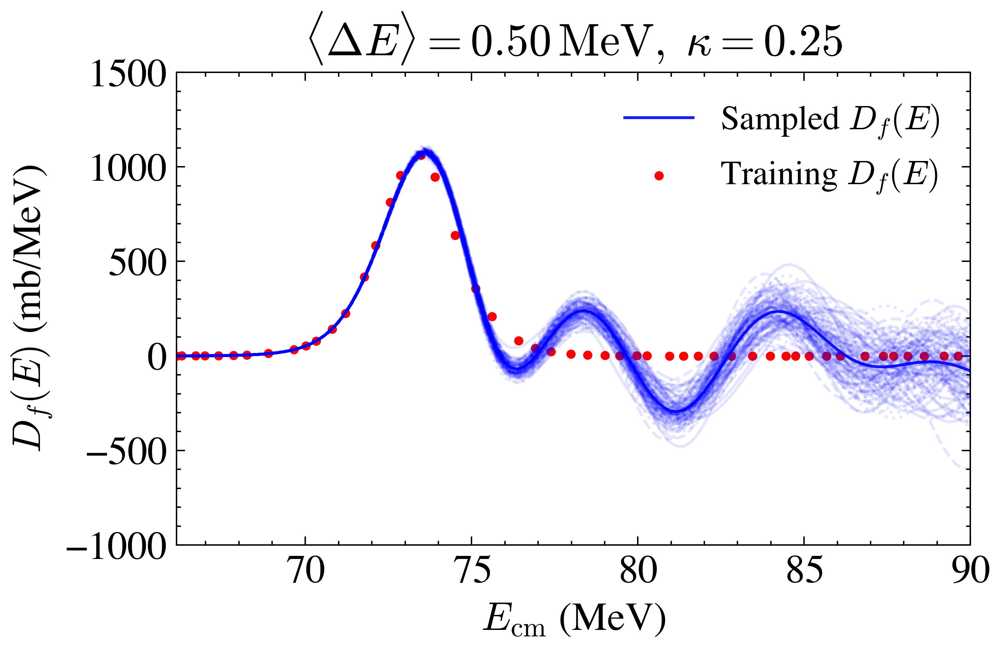

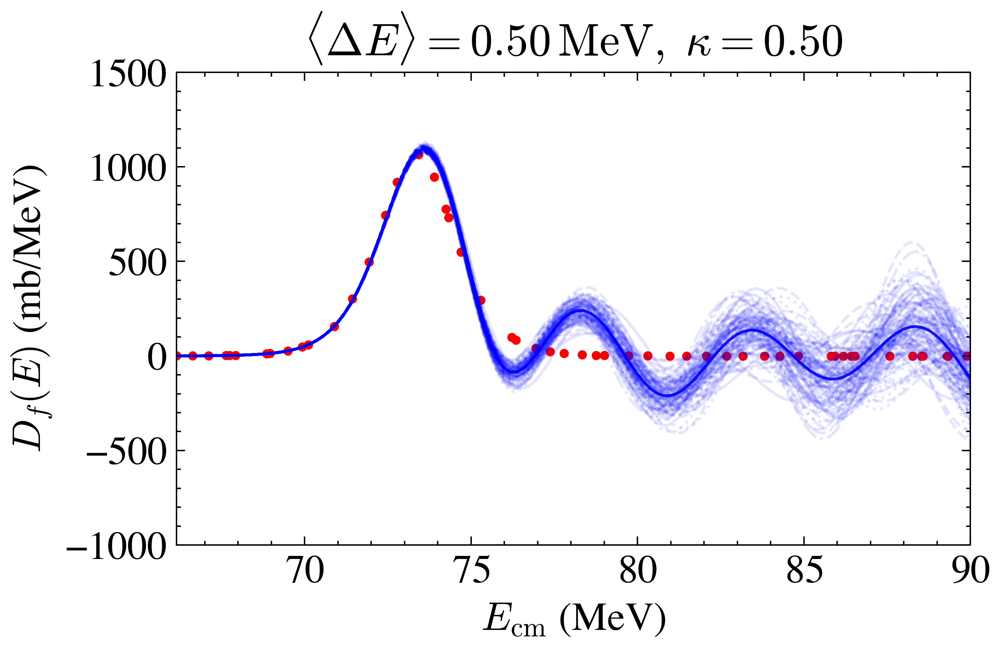

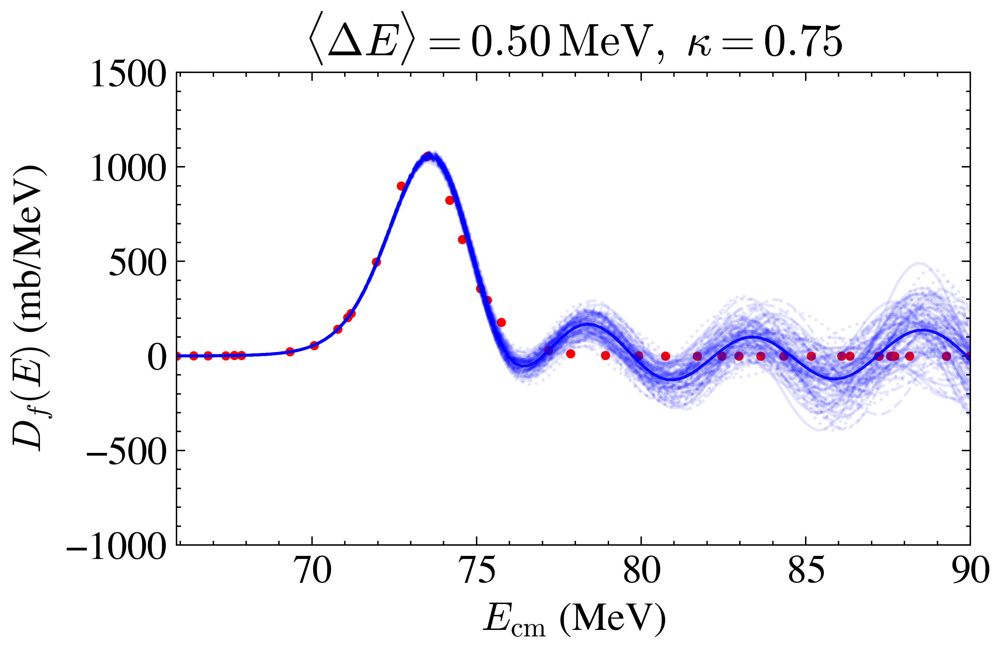

In [28]:
for cv, data in barrier_results_cv.items():
    E_tr    = data["E_tr"]
    samples = data["samples"]
    D_f_sampled_preds = np.vstack([
        barrier_dist(E_dist, samples[:, j], acc=4)
        for j in range(samples.shape[1])
    ])

    idx          = np.searchsorted(E_fine, E_tr)
    true_d_train  = true_d[idx]

    title = (
        f"$\\langle\\Delta E\\rangle = {mean_spacing:.2f}\\,\\mathrm{{MeV}},"
        f"\\;\\kappa = {cv:.2f}$"
    )

    # 5) hand off to your plotting helper
    plot_D_f(
        E_train=E_tr,
        d2_train=true_d_train,
        E_pred=E_dist,
        D_f_sampled_preds=D_f_sampled_preds,
        title=title,
        title_fontsize=16,
        axes_fontsize=14,
        ylims=[-1000,1500],
        xlims=[E_tr[0], 90],
        save_dir="../plots", #"..",
        legend=True if cv == 0.25 else False,
        save_extra=f"log_barrier_cv_{cv:.2f}_0.5" if log else f"barrier_cv_{cv:.2f}_0.5",
    )

### Experiment 4: Average Spacing of 1 MeV

In [18]:
cv_values    = [0.0, 0.25, 0.5, 0.75]
mean_spacing = 1.0   # MeV
rng          = np.random.default_rng(0)

# find your limits from existing E_fine
stop_idx = -1#np.argmin(np.abs(E_fine - 80.0))
E_min, E_max = E_fine[0], E_fine[stop_idx]

# evaluation grid — save once
E_dist = np.arange(E_min - 5, E_max + 5, 0.2)
if save_data:
    np.save("../data/E_dist_cv_1MEV.npy", E_dist)

for cv in cv_values:
    std_sp = mean_spacing * cv
    N      = int((E_max - E_min) / mean_spacing) + 5

    # 1) build irregular E_tr
    dE_sim = np.random.normal(mean_spacing, std_sp, size=N)
    dE_sim = np.clip(dE_sim, 1e-3, None)
    E_tr   = E_min + np.cumsum(dE_sim)
    E_tr   = E_tr[E_tr <= E_max]

    # 2) interpolate and corrupt
    y_tr       = np.interp(E_tr, E_fine[:stop_idx], sigma_mean[:stop_idx])
    var_tr     = (0.01 * y_tr)**2
    y_tr_noisy = y_tr + rng.normal(0, np.sqrt(var_tr), size=y_tr.shape)

    tag = f"{cv:.2f}"
    if save_data:
        np.save(f"../data/E_tr_cv_{tag}_1MEV.npy",       E_tr)
        np.save(f"../data/y_tr_cv_{tag}_1MEV.npy",       y_tr)
        np.save(f"../data/var_tr_cv_{tag}_1MEV.npy",     var_tr)
        np.save(f"../data/y_tr_noisy_cv_{tag}_1MEV.npy", y_tr_noisy)

In [29]:
cv_values = [0.0, 0.25, 0.5, 0.75]
mean_spacing = 1.0 # 0.5   # MeV
barrier_results_cv_2 = {}

log=True
for cv in cv_values:
    tag       = f"{cv:.2f}"
    E_tr      = np.load(f"../data/E_tr_cv_{tag}_1MEV.npy")
    y_tr_noisy= np.load(f"../data/y_tr_noisy_cv_{tag}_1MEV.npy")
    var_tr    = np.load(f"../data/var_tr_cv_{tag}_1MEV.npy")

    gp = train_gp(E_tr, y_tr_noisy, var_tr, log=log)
    samples = np.exp(gp.sample_y(E_dist.reshape(-1, 1), n_samples=n_samples)) if log else gp.sample_y(E_dist.reshape(-1, 1), n_samples=n_samples)

    barrier_results_cv_2[cv] = {
        "E_tr":    E_tr,
        "y_tr":    y_tr_noisy,
        "var_tr":  var_tr,
        "samples": samples
    }

130731.259835929
128949.3682940459


/Users/aaronphilip/envs/autobnn/lib/python3.10/site-packages/sklearn/gaussian_process/_gpr.py:659: ConvergenceWarning: lbfgs failed to converge (status=2):
ABNORMAL: .

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)


126207.92965957476
140216.56345032266


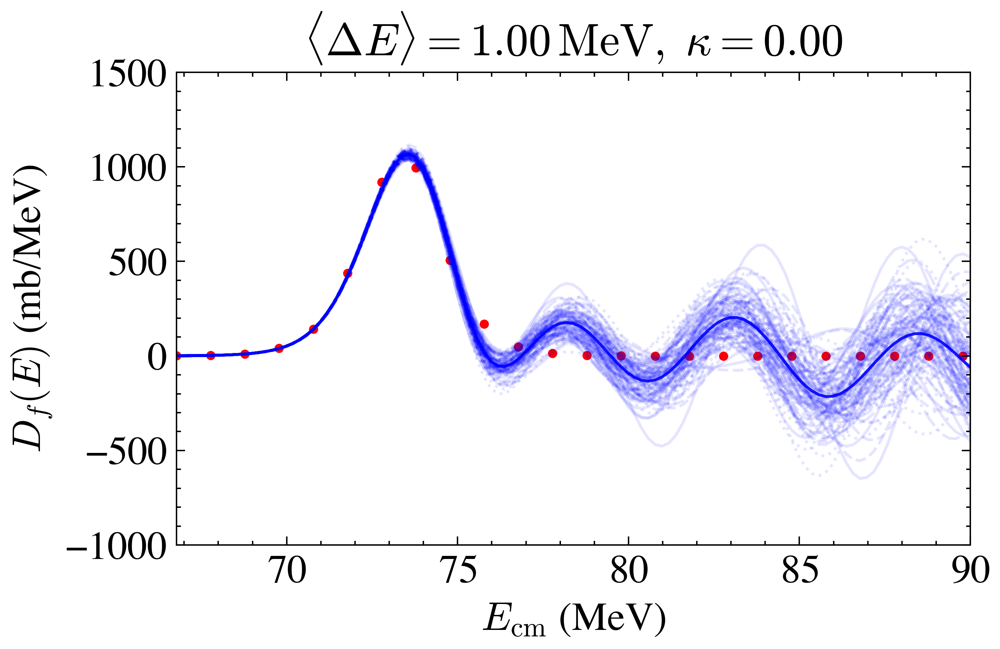

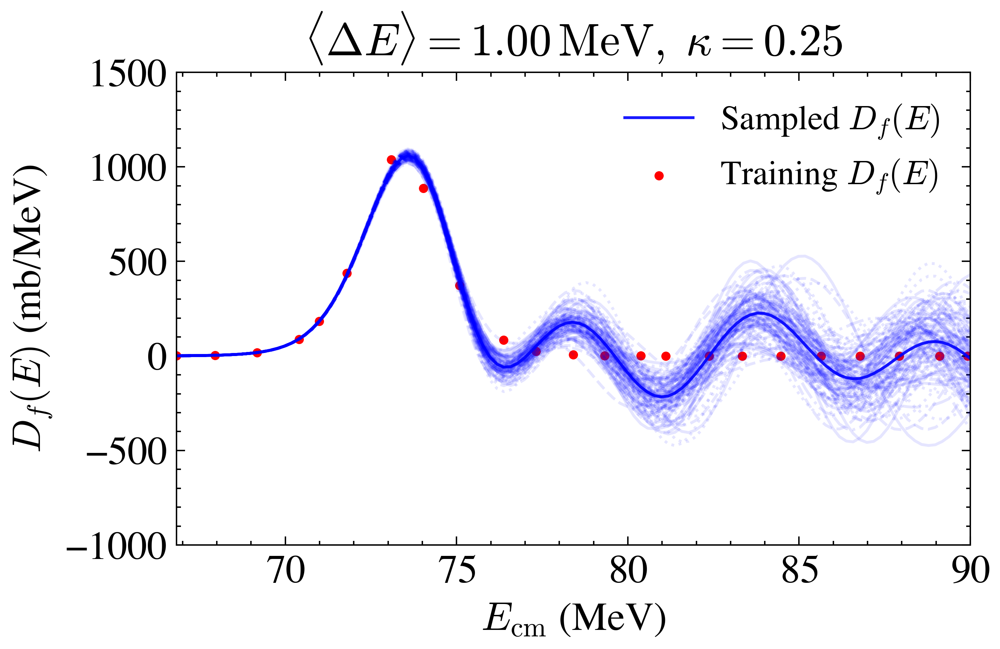

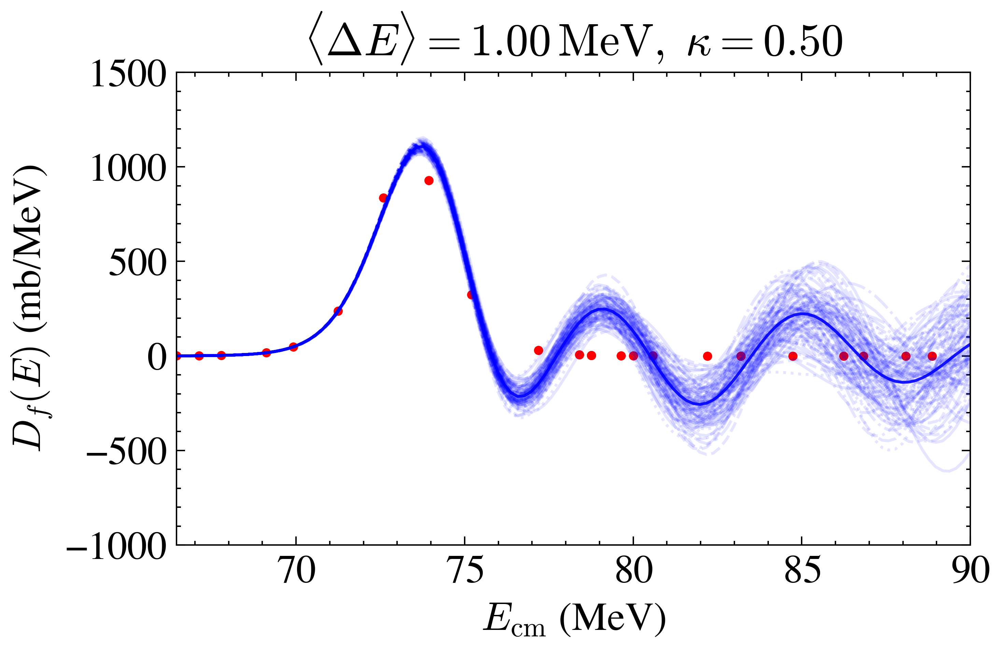

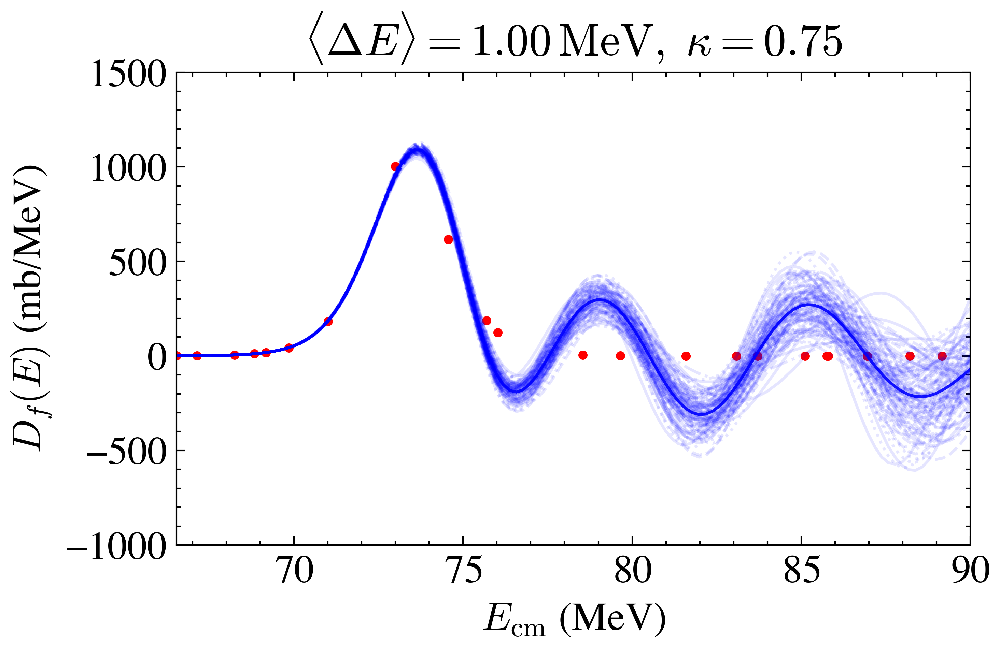

In [30]:
for cv, data in barrier_results_cv_2.items():
    E_tr    = data["E_tr"]
    samples = data["samples"]
    D_f_sampled_preds = np.vstack([
        barrier_dist(E_dist, samples[:, j], acc=4)
        for j in range(samples.shape[1])
    ])

    idx          = np.searchsorted(E_fine, E_tr)
    true_d_train  = true_d[idx]

    title = (
        f"$\\langle\\Delta E\\rangle = {mean_spacing:.2f}\\,\\mathrm{{MeV}},"
        f"\\;\\kappa = {cv:.2f}$"
    )

    # 5) hand off to your plotting helper
    plot_D_f(
        E_train=E_tr,
        d2_train=true_d_train,
        E_pred=E_dist,
        D_f_sampled_preds=D_f_sampled_preds,
        title=title,
        title_fontsize=16,
        axes_fontsize=14,
        xlims=[E_tr[0], 90],
        ylims=[-1000,1500],
        save_dir="../plots", #"..",
        legend=True if cv == 0.25 else False,
        save_extra=f"log_barrier_cv_{cv:.2f}_1.0" if log else f"barrier_cv_{cv:.2f}_1.0",
    )

### Big Picture Conclusions: 

- The GP begins to miss the barrier when the estimated error to sigma ratio is between order of magnitudes 0.01 and 0.1. 
- In general, adding a White Noise kernel has little to no effect when included as the optimizer tries to minimize the noise level. 

- At characteristic resolutions of realistic experimental data, one can actually have very sparse data if the noise ratio is around $10^{-2}$

- We quantify irregularity of our data by the CV of the step sizes. Again, so long as noise ratio is low, one can use very irregular data and still capture the height and location of the barrier well. 